In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import machine_learning_models as mlm
pd.set_option('display.max_rows', 100)

In [4]:
df = pd.read_csv(r'C:\Users\mechz\Documents\Jobs_Analysis\job_postings.csv')
X = df.drop(columns=['salary_year_avg'])
predictors = X.columns.to_list()
numerical_columns = ['job_posted_year', 'job_posted_month_sine']
numerical_indices = X.columns.get_indexer(numerical_columns)
X = X.to_numpy()
y = np.where(df['salary_year_avg'] > df['salary_year_avg'].median(), 1, 0)

training_index, testing_index = mlm.train_test_split(X.shape[0], 10000)
X_training = X[training_index]
y_training = y[training_index]
X_testing = X[testing_index]
y_testing = y[testing_index]

for index in numerical_indices:
    mean = np.mean(X_training[:,index])
    std = np.std(X_training[:, index])
    X_training[:,index] = (X_training[:,index] - mean) / std
    X_testing[:,index] = (X_testing[:,index] - mean) / std

print(f'The mean, median, and standard deviation of the salary are {np.mean(df['salary_year_avg']):.3f}, {np.median(df['salary_year_avg']):.3f}, and {np.std(df['salary_year_avg']):.3f} respectively.')

The mean, median, and standard deviation of the salary are 122390.906, 115000.000, and 47019.486 respectively.


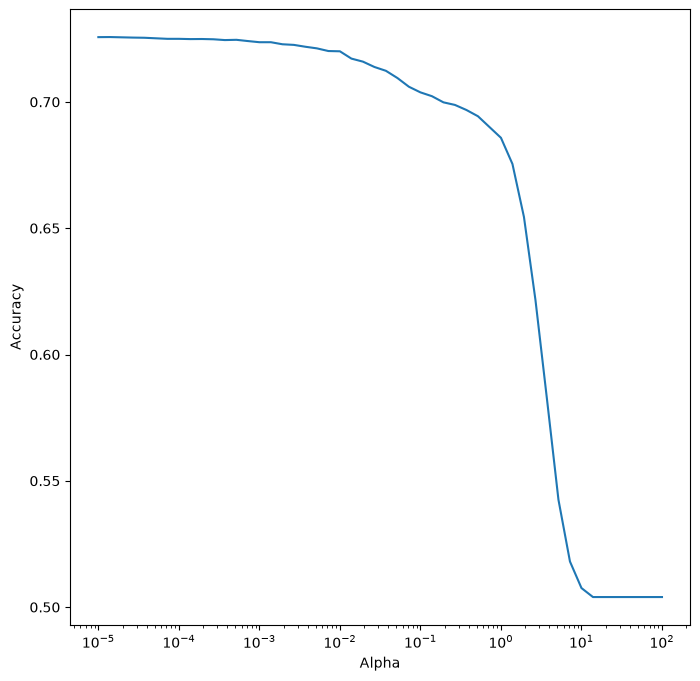

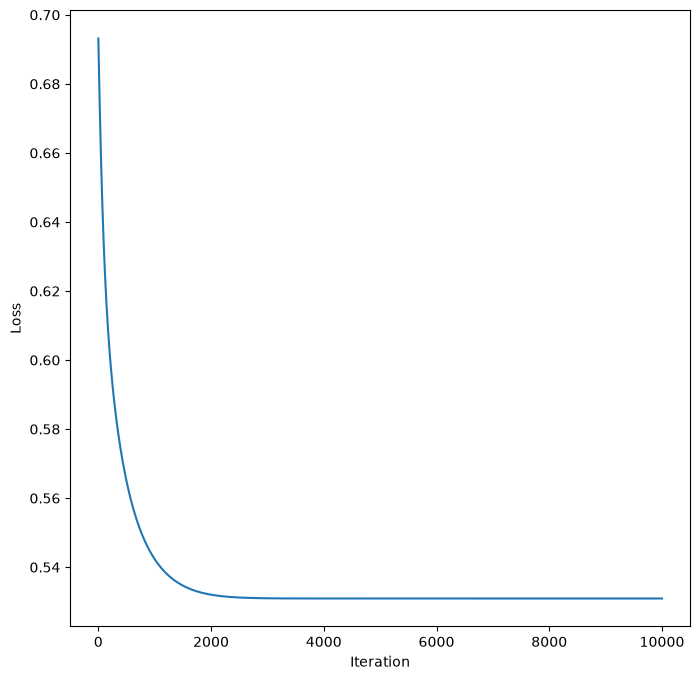

The best alpha value is 0.000 which gives a testing accuracy score of 73.700%.


,value
variable,
job_title_short_Senior Data Scientist,0.777580
job_title_short_Senior Data Engineer,0.699572
job_via_Talent.com,0.510116
job_via_Built In,0.476418
job_title_short_Software Engineer,0.471213
job_title_short_Data Scientist,0.468535
job_via_LinkedIn,0.440095
skills_snowflake,0.355208
Part-time,0.344043


In [5]:
alphas = np.logspace(-5, 2, 50)
accuracies = {}
for alpha in alphas:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, X_training.shape[0]):
        inner_model = mlm.Logistic_Regression()
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0), alpha=alpha)
        predictions = inner_model.predict(X_training[fold])
        predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    average_accuracy = np.mean(accuracies_one_fold)
    accuracies.update({alpha:average_accuracy})
best_alpha = max(accuracies, key=accuracies.get)

fig, ax = plt.subplots(figsize=(8,8))
ax.semilogx(accuracies.keys(), accuracies.values())
ax.set_xlabel('Alpha')
ax.set_ylabel('Accuracy')
plt.show()

final_model = mlm.Logistic_Regression(max_iterations=10000, record_losses=True)
final_model.fit(X_training, y_training, alpha=best_alpha)
predictions = final_model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(final_model.iterations, final_model.losses)
ax.set_xlabel('Iteration')
ax.set_ylabel('Loss')
plt.show()

print(f'The best alpha value is {best_alpha:.3f} which gives a testing accuracy score of {accuracy:.3%}.')
full_model = mlm.Logistic_Regression()
full_model.fit(X, y, alpha=best_alpha)
parameters = ['intercept'] + predictors
parameters_dictionary = dict(zip(parameters, np.insert(full_model.parameters.reshape(-1).copy(), 0, full_model.bias)))
parameters_df = pd.DataFrame([parameters_dictionary])
parameters_df = pd.melt(parameters_df).set_index('variable', drop=True).sort_values(by='value', ascending=False)
display(parameters_df)

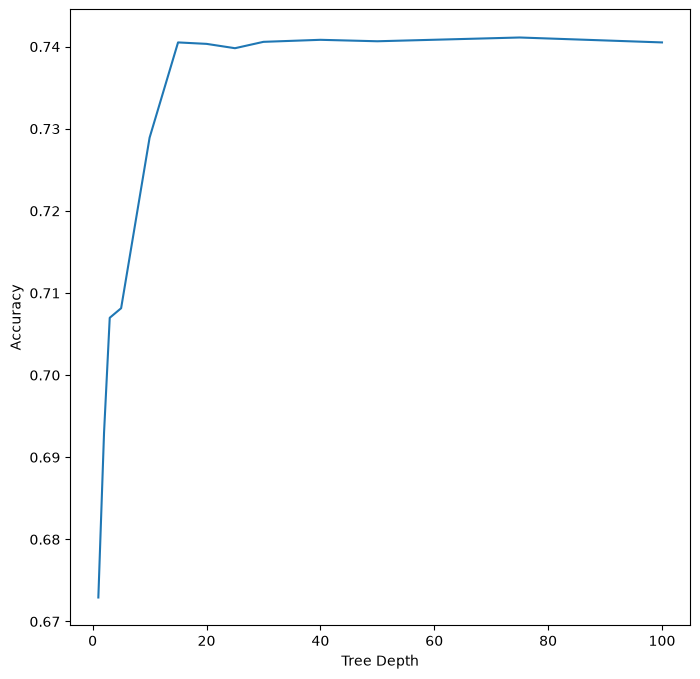

The best tree depth is 75 which gives a testing accuracy score of 0.741.


,importance,direction
variables,,
job_title_short_Data Analyst,0.362107,-0.443764
job_title_short_Business Analyst,0.056017,-0.313161
job_health_insurance,0.038425,0.111418
job_title_short_Senior Data Analyst,0.034952,-0.201424
job_posted_month_sine,0.032262,-0.001054
skills_excel,0.031939,-0.142136
job_via_Ladders,0.029570,0.028685
job_title_short_Senior Data Scientist,0.021753,0.120815
job_posted_year,0.021395,0.040743


In [6]:
depths = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
accuracies = []
for depth in depths:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Classification_Tree(X.shape[1], max_depth=depth)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold))
        predictions = inner_model.predict(X_training[fold])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append(np.mean(accuracies_one_fold))
highest_accuracy = max(accuracies)
best_depth = depths[accuracies.index(highest_accuracy)]

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(depths, accuracies)
ax.set_xlabel('Tree Depth')
ax.set_ylabel('Accuracy')
plt.show()

full_model = mlm.Regression_Tree(X.shape[1], max_depth=best_depth)
full_model.fit(X_training, y_training)
predictions = inner_model.predict(X_testing)
accuracy = np.sum(predictions == y_testing) / len(y_testing)

print(f'The best tree depth is {best_depth} which gives a testing accuracy score of {accuracy:.3f}.')
parameters = predictors
parameters_dictionary = {'variables':parameters, 'importance':full_model.features_importance(), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

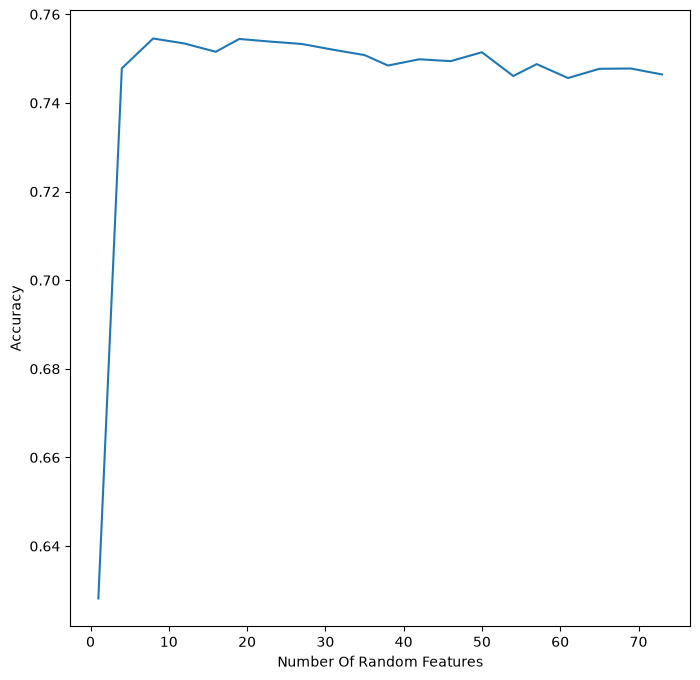

The best number of random features is 8 which gives a testing accuracy of 0.782.


,importance,direction
variables,,
job_posted_month_sine,0.096367,0.003382
job_posted_year,0.031791,0.022791
skills_other,0.029282,-0.007842
skills_sql,0.028245,0.010204
skills_azure,0.023915,0.011744
skills_tableau,0.023591,-0.022000
skills_r,0.023466,-0.001264
job_health_insurance,0.022263,0.066001
job_no_degree_mention,0.021726,-0.014708


In [ ]:
random_feature_numbers = np.unique(np.linspace(1, X_training.shape[1], 25).astype(np.int32))
accuracies = []
for random_feature_number in random_feature_numbers:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Classification_Random_Forest(number_of_trees=25, number_of_random_features=random_feature_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append([np.mean(accuracies_one_fold), random_feature_number])
accuracies = np.array(accuracies)
row_number = np.argmax(accuracies[:, 0])
best_random_feature_number = int(accuracies[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(accuracies[:, 1], accuracies[:, 0])
ax.set_xlabel('Number Of Random Features')
ax.set_ylabel('Accuracy')
plt.show()

full_model = mlm.Classification_Random_Forest(number_of_trees=500, number_of_random_features=best_random_feature_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)

print(f'The best number of random features is {best_random_feature_number} which gives a testing accuracy of {accuracy:.3f}.')
parameters = predictors
parameters_dictionary = {'variables':parameters, 'importance':full_model.features_importance(), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)